# Linear Regression From Scratch

A hands-on investigation of linear regression, squared-error cost, and gradient descent.

**Experimental structure:** The initial experiments use all 150 observations to demonstrate predictions, cost, and optimization. The final model is subsequently initialized from scratch and trained using only the 120 training observations. The remaining 30 observations are reserved for final evaluation.

In [4]:
from pathlib import Path
import sys

print("Working directory:", Path.cwd())
print("Python executable:", sys.executable)

Working directory: /Users/sql_wick/Projects/linear-regression-from-scratch
Python executable: /Users/sql_wick/Projects/linear-regression-from-scratch/.venv/bin/python


## 1. Load the Iris Dataset

We use Fisher's Iris dataset, which contains 150 flower observations and four measurements per flower.

In [5]:
from sklearn.datasets import load_iris

iris = load_iris()

print(iris.feature_names)
print(iris.data.shape)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
(150, 4)


## 2. Select the Input and Target

Sepal length is our input (x), and petal length is our target (y). Both measurements are in centimeters.

In [6]:
x = iris.data[:, 0]
y = iris.data[:, 2]

for i in range(5):
    print(f"Flower {i+1}: Sepal = {x[i]} cm, Petal = {y[i]} cm")

Flower 1: Sepal = 5.1 cm, Petal = 1.4 cm
Flower 2: Sepal = 4.9 cm, Petal = 1.4 cm
Flower 3: Sepal = 4.7 cm, Petal = 1.3 cm
Flower 4: Sepal = 4.6 cm, Petal = 1.5 cm
Flower 5: Sepal = 5.0 cm, Petal = 1.4 cm


## 3. Explore the Observations

A scatter plot helps us examine the relationship before selecting a model.

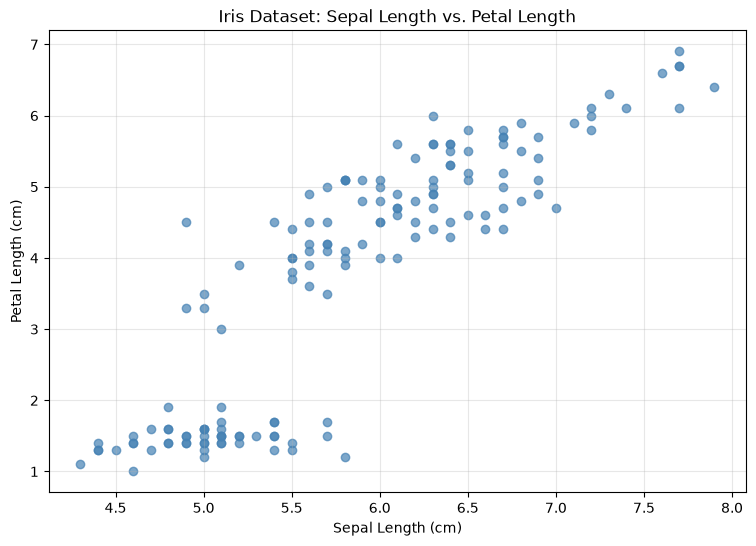

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(x, y, color="steelblue", alpha=0.7)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Iris Dataset: Sepal Length vs. Petal Length")

plt.grid(True, alpha=0.3)
plt.show()

## 4. Make Predictions Using a Straight Line

Our model uses f(x) = wx + b. We initially choose the parameters manually to observe their effect.

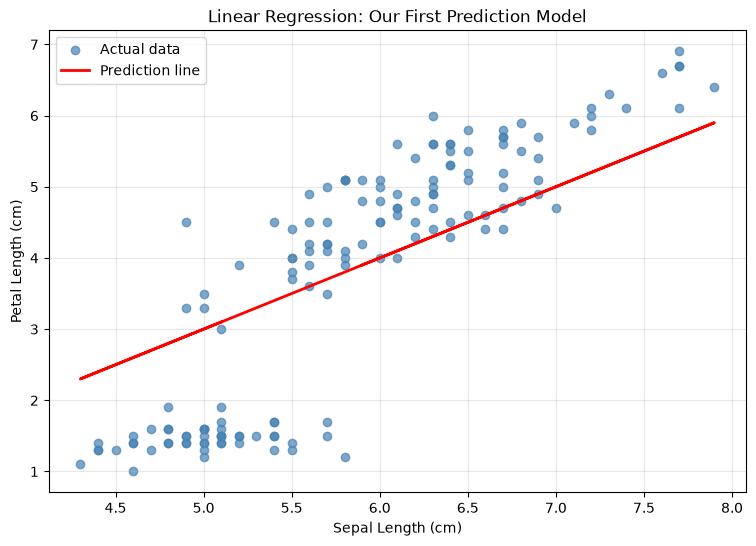

In [8]:
w = 1.0
b = -2.0

# Calculate predictions
y_pred = w * x + b

# Plot the actual observations
plt.figure(figsize=(9, 6))
plt.scatter(x, y, color="steelblue", alpha=0.7, label="Actual data")

# Plot our model's predictions
plt.plot(x, y_pred, color="red", linewidth=2, label="Prediction line")

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Linear Regression: Our First Prediction Model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Calculate the Squared-Error Cost

The cost function measures prediction error. Squaring prevents positive and negative errors from canceling and penalizes larger mistakes more heavily.

In [9]:
# Number of training examples
m = len(y)

# Difference between predictions and actual values
errors = y_pred - y

# Square each error
squared_errors = errors ** 2

# Calculate Andrew Ng's cost function
cost = sum(squared_errors) / (2 * m)

print(f"Number of examples: {m}")
print(f"Cost: {cost:.4f}")

Number of examples: 150
Cost: 0.6261


## 6. Experiment with Model Parameters

In [10]:
w = 1.0

for b in [-3.0, -2.0, -1.0, 0.0]:
    predictions = w * x + b
    errors = predictions - y
    cost = sum(errors ** 2) / (2 * len(y))

    print(f"w = {w:.1f}, b = {b:.1f}, cost = {cost:.4f}")

w = 1.0, b = -3.0, cost = 1.0408
w = 1.0, b = -2.0, cost = 0.6261
w = 1.0, b = -1.0, cost = 1.2115
w = 1.0, b = 0.0, cost = 2.7968


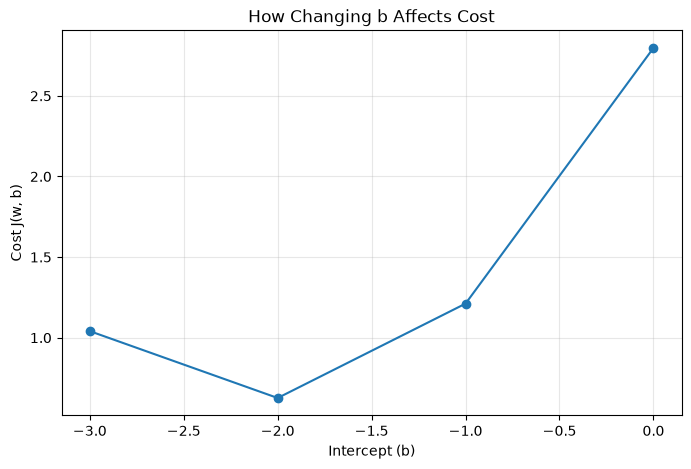

In [11]:
w = 1.0

b_values = [-3.0, -2.0, -1.0, 0.0]
costs = []

for b in b_values:
    predictions = w * x + b
    errors = predictions - y
    cost = sum(errors ** 2) / (2 * len(y))
    costs.append(cost)

plt.figure(figsize=(8, 5))
plt.plot(b_values, costs, marker="o")

plt.xlabel("Intercept (b)")
plt.ylabel("Cost J(w, b)")
plt.title("How Changing b Affects Cost")

plt.grid(True, alpha=0.3)
plt.show()

## 7. Visualize the Cost Function

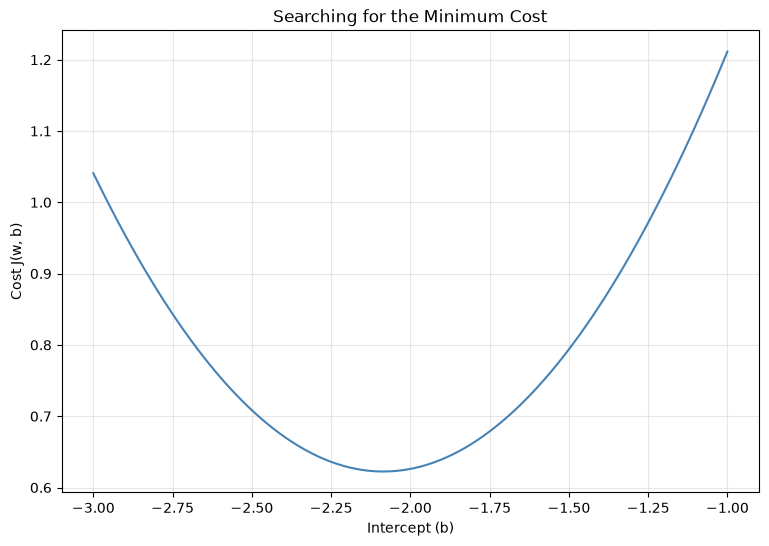

In [12]:
import numpy as np

w = 1.0

# Generate 100 possible intercept values
b_values = np.linspace(-3, -1, 100)

costs = []

for b in b_values:
    predictions = w * x + b
    errors = predictions - y
    cost = sum(errors ** 2) / (2 * len(y))
    costs.append(cost)

plt.figure(figsize=(9, 6))
plt.plot(b_values, costs, color="steelblue")

plt.xlabel("Intercept (b)")
plt.ylabel("Cost J(w, b)")
plt.title("Searching for the Minimum Cost")

plt.grid(True, alpha=0.3)
plt.show()

## 8. Gradient Descent for the Intercept

We first optimize only the intercept while holding the slope constant. This isolates one parameter and makes the optimization process easier to visualize.

In [13]:
# Starting parameters
w = 1.0
b = 0.0

learning_rate = 0.1
iterations = 50

m = len(y)

for i in range(iterations):

    # Make predictions
    predictions = w * x + b

    # Calculate prediction errors
    errors = predictions - y

    # Calculate gradient for b
    gradient_b = sum(errors) / m

    # Update b
    b = b - learning_rate * gradient_b

    # Measure updated cost
    new_predictions = w * x + b
    cost = sum((new_predictions - y) ** 2) / (2 * m)

    if i % 5 == 0:
        print(f"Iteration {i:2d}: b = {b:.4f}, cost = {cost:.4f}")

Iteration  0: b = -0.2085, cost = 2.3837
Iteration  5: b = -0.9771, cost = 1.2366
Iteration 10: b = -1.4309, cost = 0.8366
Iteration 15: b = -1.6989, cost = 0.6972
Iteration 20: b = -1.8572, cost = 0.6485
Iteration 25: b = -1.9506, cost = 0.6316
Iteration 30: b = -2.0058, cost = 0.6257
Iteration 35: b = -2.0384, cost = 0.6236
Iteration 40: b = -2.0576, cost = 0.6229
Iteration 45: b = -2.0690, cost = 0.6226


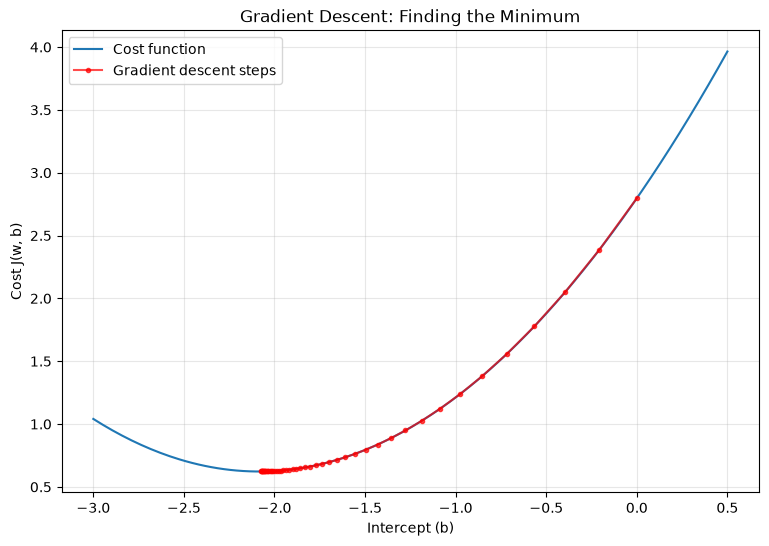

In [14]:
w = 1.0
b = 0.0

learning_rate = 0.1
iterations = 50
m = len(y)

b_history = []
cost_history = []

for i in range(iterations):
    predictions = w * x + b
    errors = predictions - y

    cost = sum(errors ** 2) / (2 * m)

    # Record position before updating
    b_history.append(b)
    cost_history.append(cost)

    gradient_b = sum(errors) / m
    b = b - learning_rate * gradient_b

# Plot the cost curve
b_values = np.linspace(-3, 0.5, 200)

curve_costs = [
    sum((w * x + test_b - y) ** 2) / (2 * m)
    for test_b in b_values
]

plt.figure(figsize=(9, 6))

plt.plot(b_values, curve_costs, label="Cost function")

plt.plot(
    b_history,
    cost_history,
    "o-",
    color="red",
    markersize=3,
    alpha=0.7,
    label="Gradient descent steps"
)

plt.xlabel("Intercept (b)")
plt.ylabel("Cost J(w, b)")
plt.title("Gradient Descent: Finding the Minimum")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 9. Gradient Descent for Both Parameters

We extend gradient descent to update both the slope and intercept using gradients calculated from the same set of predictions.

In [15]:
# Initial model parameters
w = 0.0
b = 0.0

learning_rate = 0.01
iterations = 5000
m = len(y)

cost_history = []

for i in range(iterations):
    predictions = w * x + b
    errors = predictions - y

    # Gradients for both parameters
    gradient_w = sum(errors * x) / m
    gradient_b = sum(errors) / m

    # Update both parameters
    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b

    # Calculate cost after the update
    predictions = w * x + b
    cost = sum((predictions - y) ** 2) / (2 * m)
    cost_history.append(cost)

    if i % 500 == 0:
        print(
            f"Iteration {i:4d}: "
            f"w = {w:.4f}, "
            f"b = {b:.4f}, "
            f"cost = {cost:.4f}"
        )

print(f"\nFinal parameters: w = {w:.4f}, b = {b:.4f}")
print(f"Final cost: {cost:.4f}")

Iteration    0: w = 0.2323, b = 0.0376, cost = 4.0647
Iteration  500: w = 0.7580, b = -0.5467, cost = 0.7917
Iteration 1000: w = 0.8579, b = -1.1414, cost = 0.7189
Iteration 1500: w = 0.9487, b = -1.6822, cost = 0.6587
Iteration 2000: w = 1.0312, b = -2.1740, cost = 0.6090
Iteration 2500: w = 1.1063, b = -2.6211, cost = 0.5678
Iteration 3000: w = 1.1745, b = -3.0276, cost = 0.5338
Iteration 3500: w = 1.2366, b = -3.3972, cost = 0.5057
Iteration 4000: w = 1.2930, b = -3.7333, cost = 0.4825
Iteration 4500: w = 1.3443, b = -4.0390, cost = 0.4632

Final parameters: w = 1.3909, b = -4.3163
Final cost: 0.4474


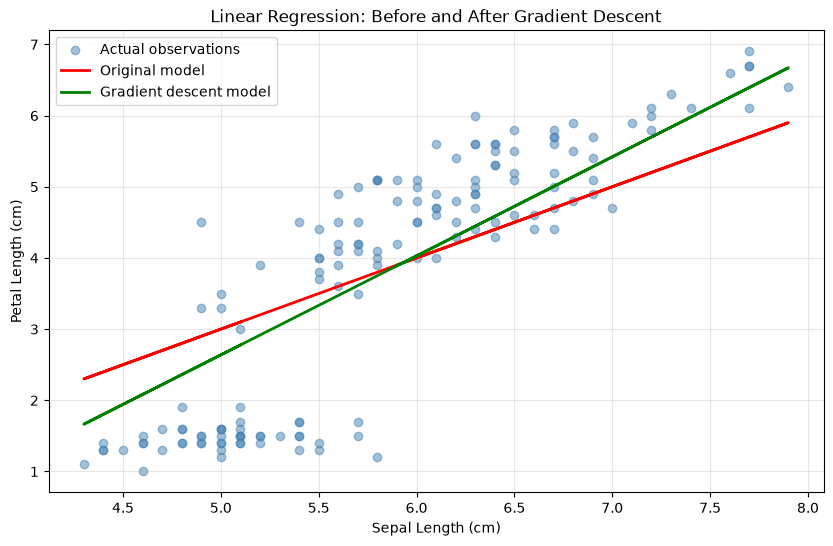

In [16]:
# Predictions from our original model
original_predictions = 1.0 * x - 2.0

# Predictions using our optimized parameters
optimized_predictions = w * x + b

plt.figure(figsize=(10, 6))

# Actual flower measurements
plt.scatter(
    x, y,
    color="steelblue",
    alpha=0.5,
    label="Actual observations"
)

# Original prediction line
plt.plot(
    x, original_predictions,
    color="red",
    linewidth=2,
    label="Original model"
)

# Gradient descent prediction line
plt.plot(
    x, optimized_predictions,
    color="green",
    linewidth=2,
    label="Gradient descent model"
)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Linear Regression: Before and After Gradient Descent")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 10. Create Training and Test Sets

We reserve 20% of the observations for testing. The following training procedure uses only the remaining 80%.

In [17]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print(f"Training examples: {len(x_train)}")
print(f"Testing examples: {len(x_test)}")

Training examples: 120
Testing examples: 30


## 11. Train Using Only Training Data

In [18]:
# Reset our parameters
w = 0.0
b = 0.0

learning_rate = 0.01
iterations = 5000

m = len(y_train)
cost_history = []

for i in range(iterations):
    # Predict using training data only
    predictions = w * x_train + b

    # Calculate prediction errors
    errors = predictions - y_train

    # Calculate gradients
    gradient_w = sum(errors * x_train) / m
    gradient_b = sum(errors) / m

    # Update both parameters
    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b

    # Record training cost
    predictions = w * x_train + b
    cost = sum((predictions - y_train) ** 2) / (2 * m)
    cost_history.append(cost)

print(f"Final w: {w:.4f}")
print(f"Final b: {b:.4f}")
print(f"Training cost: {cost:.4f}")

Final w: 1.3747
Final b: -4.2077
Training cost: 0.4631


## 12. Initial Test Evaluation

In [19]:
# Predict petal lengths for unseen flowers
test_predictions = w * x_test + b

# Calculate test prediction errors
test_errors = test_predictions - y_test

# Calculate test cost
test_cost = sum(test_errors ** 2) / (2 * len(y_test))

print(f"Training cost: {cost:.4f}")
print(f"Testing cost:  {test_cost:.4f}")

Training cost: 0.4631
Testing cost:  0.4151


## 13. Inspect Individual Prediction Errors

In [20]:
# Compare actual and predicted petal lengths
for i in range(10):
    actual = y_test[i]
    predicted = test_predictions[i]
    error = predicted - actual

    print(
        f"Flower {i+1:2d} | "
        f"Actual: {actual:.2f} cm | "
        f"Predicted: {predicted:.2f} cm | "
        f"Error: {error:+.2f} cm"
    )

Flower  1 | Actual: 4.70 cm | Predicted: 4.18 cm | Error: -0.52 cm
Flower  2 | Actual: 1.70 cm | Predicted: 3.63 cm | Error: +1.93 cm
Flower  3 | Actual: 6.90 cm | Predicted: 6.38 cm | Error: -0.52 cm
Flower  4 | Actual: 4.50 cm | Predicted: 4.04 cm | Error: -0.46 cm
Flower  5 | Actual: 4.80 cm | Predicted: 5.14 cm | Error: +0.34 cm
Flower  6 | Actual: 1.50 cm | Predicted: 3.22 cm | Error: +1.72 cm
Flower  7 | Actual: 3.60 cm | Predicted: 3.49 cm | Error: -0.11 cm
Flower  8 | Actual: 5.10 cm | Predicted: 5.28 cm | Error: +0.18 cm
Flower  9 | Actual: 4.50 cm | Predicted: 4.32 cm | Error: -0.18 cm
Flower 10 | Actual: 3.90 cm | Predicted: 3.77 cm | Error: -0.13 cm


## 14. Analyze Residuals

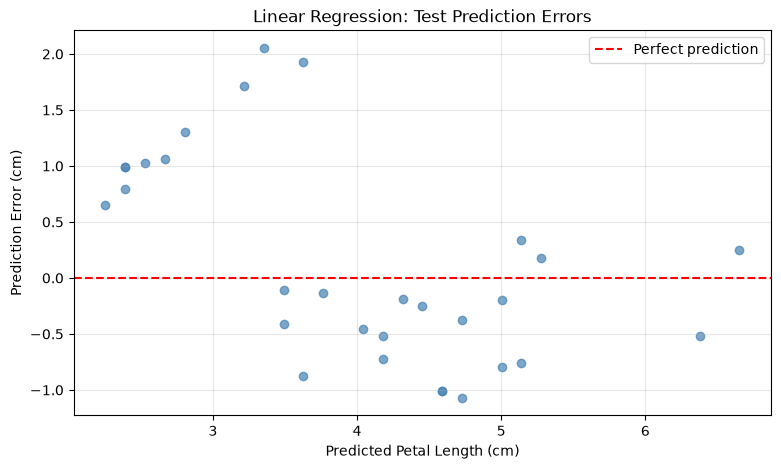

In [21]:
# Calculate errors for all 30 test flowers
test_errors = test_predictions - y_test

plt.figure(figsize=(9, 5))

plt.scatter(
    test_predictions,
    test_errors,
    color="steelblue",
    alpha=0.7
)

# Zero error reference
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Predicted Petal Length (cm)")
plt.ylabel("Prediction Error (cm)")
plt.title("Linear Regression: Test Prediction Errors")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 15. Visualize Training Convergence

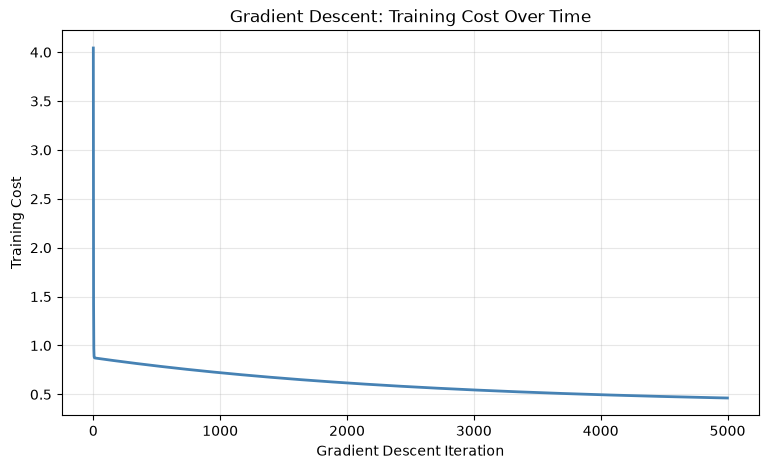

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    cost_history,
    color="steelblue",
    linewidth=2
)

plt.xlabel("Gradient Descent Iteration")
plt.ylabel("Training Cost")
plt.title("Gradient Descent: Training Cost Over Time")

plt.grid(True, alpha=0.3)
plt.show()

## 16. Continue Optimization

The first training run had not fully converged. We continue optimization without resetting the parameters or introducing test observations.

In [23]:
# Continue training from our existing w and b
additional_iterations = 20000

m = len(y_train)

for i in range(additional_iterations):
    predictions = w * x_train + b
    errors = predictions - y_train

    gradient_w = sum(errors * x_train) / m
    gradient_b = sum(errors) / m

    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b

    predictions = w * x_train + b
    cost = sum((predictions - y_train) ** 2) / (2 * m)

    cost_history.append(cost)

    if (i + 1) % 5000 == 0:
        print(
            f"Additional iteration {i+1:5d}: "
            f"w = {w:.4f}, "
            f"b = {b:.4f}, "
            f"cost = {cost:.4f}"
        )

Additional iteration  5000: w = 1.6565, b = -5.8761, cost = 0.4016
Additional iteration 10000: w = 1.7654, b = -6.5209, cost = 0.3924
Additional iteration 15000: w = 1.8075, b = -6.7701, cost = 0.3910
Additional iteration 20000: w = 1.8237, b = -6.8664, cost = 0.3908


## 17. Independently Verify the Parameters

We compare our gradient descent solution with NumPy's least-squares solution to independently check the optimization result.

In [24]:
# Independent reference using NumPy
reference_w, reference_b = np.polyfit(x_train, y_train, 1)

print("Gradient descent:")
print(f"  w = {w:.6f}")
print(f"  b = {b:.6f}")
print(f"  cost = {cost:.6f}")

reference_predictions = reference_w * x_train + reference_b
reference_cost = np.mean((reference_predictions - y_train) ** 2) / 2

print("\nLeast-squares reference:")
print(f"  w = {reference_w:.6f}")
print(f"  b = {reference_b:.6f}")
print(f"  cost = {reference_cost:.6f}")

print(f"\nCost difference: {cost - reference_cost:.8f}")

Gradient descent:
  w = 1.823716
  b = -6.866448
  cost = 0.390808

Least-squares reference:
  w = 1.833963
  b = -6.927128
  cost = 0.390772

Cost difference: 0.00003600


## 18. Evaluate the Final Model

The final model is evaluated on held-out data. We report squared-error cost and mean absolute error.

In [25]:
# Evaluate our final gradient descent model
final_test_predictions = w * x_test + b

# Prediction errors
final_test_errors = final_test_predictions - y_test

# Final testing cost
final_test_cost = sum(final_test_errors ** 2) / (2 * len(y_test))

# Mean absolute error (average error magnitude)
mae = np.mean(np.abs(final_test_errors))

print(f"Final training cost: {cost:.6f}")
print(f"Final testing cost:  {final_test_cost:.6f}")
print(f"Mean absolute error: {mae:.4f} cm")

Final training cost: 0.390808
Final testing cost:  0.299055
Mean absolute error: 0.6186 cm


## 19. Conclusions and Limitations

### Objective

This experiment investigated whether iris petal length could
be predicted from sepal length using univariate linear regression.

### Implementation

The prediction function, squared-error cost function, and
batch gradient descent algorithm were implemented directly
using Python and NumPy.

Gradient descent was used to optimize both model parameters.

### Final Results

| Measurement | Result |
|---|---:|
| Training observations | 120 |
| Test observations | 30 |
| Learning rate | 0.01 |
| Total gradient descent iterations | 25,000 |
| Final weight (w) | 1.823716 |
| Final bias (b) | -6.866448 |
| Training cost | 0.390808 |
| Test cost | 0.299055 |
| Test mean absolute error | 0.6186 cm |
| Least-squares reference cost | 0.390772 |

### Verification

Gradient descent approached the independent least-squares
solution, with a training cost difference of approximately
0.000036.

This provides evidence that the gradient calculations
and parameter updates are functioning correctly.

### Limitations

The model uses only sepal length to predict petal length.

Residual analysis revealed systematic prediction errors,
suggesting that a single straight line does not fully
represent the relationships in the dataset.

The evaluation uses one train-test split. Additional
validation would be necessary to establish how reliably
the model generalizes to other samples.

### Conclusion

Gradient descent successfully reduced the squared-error
cost and approached the least-squares solution.

However, successful optimization does not guarantee
that the chosen model adequately represents the data.

This experiment demonstrates the distinction between
optimizing a model and evaluating its predictive usefulness.
